# Call of Duty Player Clustering

This project segments Call of Duty players based on their in-game statistics. The dataset comes from Kaggle and contains fairly detailed per-player data: each row represents one player and their stats.

The goal is to find meaningful player groups (e.g. newcomers, average players, veterans) and to see how density-based clustering can isolate players whose stats deviate strongly from the rest.

Source: [COD dataset](https://www.kaggle.com/datasets/aishahakami/call-of-duty-players)

# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# Dataset description

- **name**: player's nickname
- **wins**: number of matches won
- **kills**: total number of kills across all matches
- **kdRatio**: kill/death ratio
- **killstreak**: number of kills in a row without dying
- **level**: player level
- **losses**: total number of losses
- **prestige**: optional progression a player can activate after reaching level 55
- **hits**: number of hits landed on opponents
- **timePlayed**: time spent playing (in hours)
- **headshots**: number of headshots
- **averageTime**: average time
- **gamesPlayed**: number of multiplayer matches played
- **assists**: number of assists (the player damaged an enemy, but a teammate finished the kill)
- **misses**: number of missed shots
- **xp**: experience points
- **scorePerMinute**: score per minute
- **shots**: number of shots fired
- **deaths**: number of deaths

### Loading the data

In [2]:
df = pd.read_csv("data/cod.csv")

In [3]:
df.head()

,name,wins,kills,kdRatio,killstreak,level,losses,prestige,hits,timePlayed,headshots,averageTime,gamesPlayed,assists,misses,xp,scorePerMinute,shots,deaths
0,RggRt45#4697369,0,0,0.00000,0,1,0,0,0,0,0,0.0,0,0,0,0,0.0,0,0
1,JohniceRex#9176033,0,0,0.00000,0,1,0,110,0,7,0,7.0,0,0,0,700,0.0,0,16
2,bootybootykill#1892064,0,66,1.03125,0,9,0,110,0,32,16,32.0,0,1,0,48300,0.0,0,64
3,JNaCo#5244172,3,2,0.40000,0,1,0,0,0,3,0,3.0,0,0,0,1150,0.0,0,5
4,gomezyayo_007#6596687,0,2,0.20000,0,1,0,110,0,5,1,5.0,0,0,0,1000,0.0,0,10


In [4]:
print(df.shape)

(1558, 19)


# EDA

First, let's look at basic information about the dataset, including the data type of each column (needed later when preparing the data for clustering).

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1558 entries, 0 to 1557
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   name            1558 non-null   str    
 1   wins            1558 non-null   int64  
 2   kills           1558 non-null   int64  
 3   kdRatio         1558 non-null   float64
 4   killstreak      1558 non-null   int64  
 5   level           1558 non-null   int64  
 6   losses          1558 non-null   int64  
 7   prestige        1558 non-null   int64  
 8   hits            1558 non-null   int64  
 9   timePlayed      1558 non-null   int64  
 10  headshots       1558 non-null   int64  
 11  averageTime     1558 non-null   float64
 12  gamesPlayed     1558 non-null   int64  
 13  assists         1558 non-null   int64  
 14  misses          1558 non-null   int64  
 15  xp              1558 non-null   int64  
 16  scorePerMinute  1558 non-null   float64
 17  shots           1558 non-null   int64  
 18 

There appear to be no missing values to drop, but let's verify that explicitly.

In [6]:
df.isnull().sum()

name              0
wins              0
kills             0
kdRatio           0
killstreak        0
level             0
losses            0
prestige          0
hits              0
timePlayed        0
headshots         0
averageTime       0
gamesPlayed       0
assists           0
misses            0
xp                0
scorePerMinute    0
shots             0
deaths            0
dtype: int64

Next, check for duplicate rows.

In [7]:
df.duplicated().sum()

np.int64(0)

Summary statistics for each column (mean, min, max, median, ...).

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
wins,1558.0,153.002567,3.019848e+02,0.0,0.000000,10.000000,168.000000,3519.0
kills,1558.0,3753.001926,7.929697e+03,0.0,4.000000,191.500000,3445.750000,66935.0
kdRatio,1558.0,0.637098,4.304593e-01,0.0,0.261442,0.732837,0.955293,3.0
killstreak,1558.0,6.895379,1.018468e+01,0.0,0.000000,5.000000,12.000000,235.0
level,1558.0,44.414634,6.831806e+01,1.0,1.000000,11.000000,51.000000,435.0
losses,1558.0,4.998074,7.005778e+00,0.0,0.000000,2.000000,8.000000,80.0
prestige,1558.0,47.657253,5.162621e+01,0.0,0.000000,14.000000,110.000000,117.0
hits,1558.0,10330.189987,2.295410e+04,0.0,0.000000,214.500000,9015.500000,209851.0
timePlayed,1558.0,425.915918,7.861825e+02,0.0,4.000000,51.000000,485.500000,7479.0
headshots,1558.0,630.672657,1.305150e+03,0.0,1.000000,32.000000,602.750000,11719.0


Many attributes have a minimum of 0. These rows should be removed, because players who have essentially never played the game are not meaningful for clustering.

In [9]:
columns_to_check = ['hits', 'shots', 'misses', 'headshots', 'scorePerMinute', 'wins', 'gamesPlayed']
rows_to_keep = (df[columns_to_check] != 0).all(axis=1)
print("Number of players to be removed from the dataset: ", rows_to_keep.shape[0] - rows_to_keep.sum())
df = df[rows_to_keep]


drop_condition = (df['level'] == 1) & (df['xp'] == 0) & (df['gamesPlayed'] == 0) & (df['hits'] == 0) & (df['shots'] == 0)
n_dropped = drop_condition.sum()

print("Number of players removed from the dataset:", n_dropped)
df = df[~drop_condition]
print(df.shape)

Number of players to be removed from the dataset:  682
Number of players removed from the dataset: 0
(876, 19)


The value ranges also need checking. Some columns, such as **kills**, **xp** or **shots**, have a very wide range (outliers). An IQR-based filter was considered for removing them:

```python
for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower) & (df[col] <= upper)]

print(df.shape)
```

*Note: this IQR filter is kept for reference only and is not executed. All subsequent steps use the dataset after zero-value filtering; the outlying players are left in so that density-based clustering (DBSCAN) can identify them.*

Now we can plot histograms to see how the values in each column are distributed.

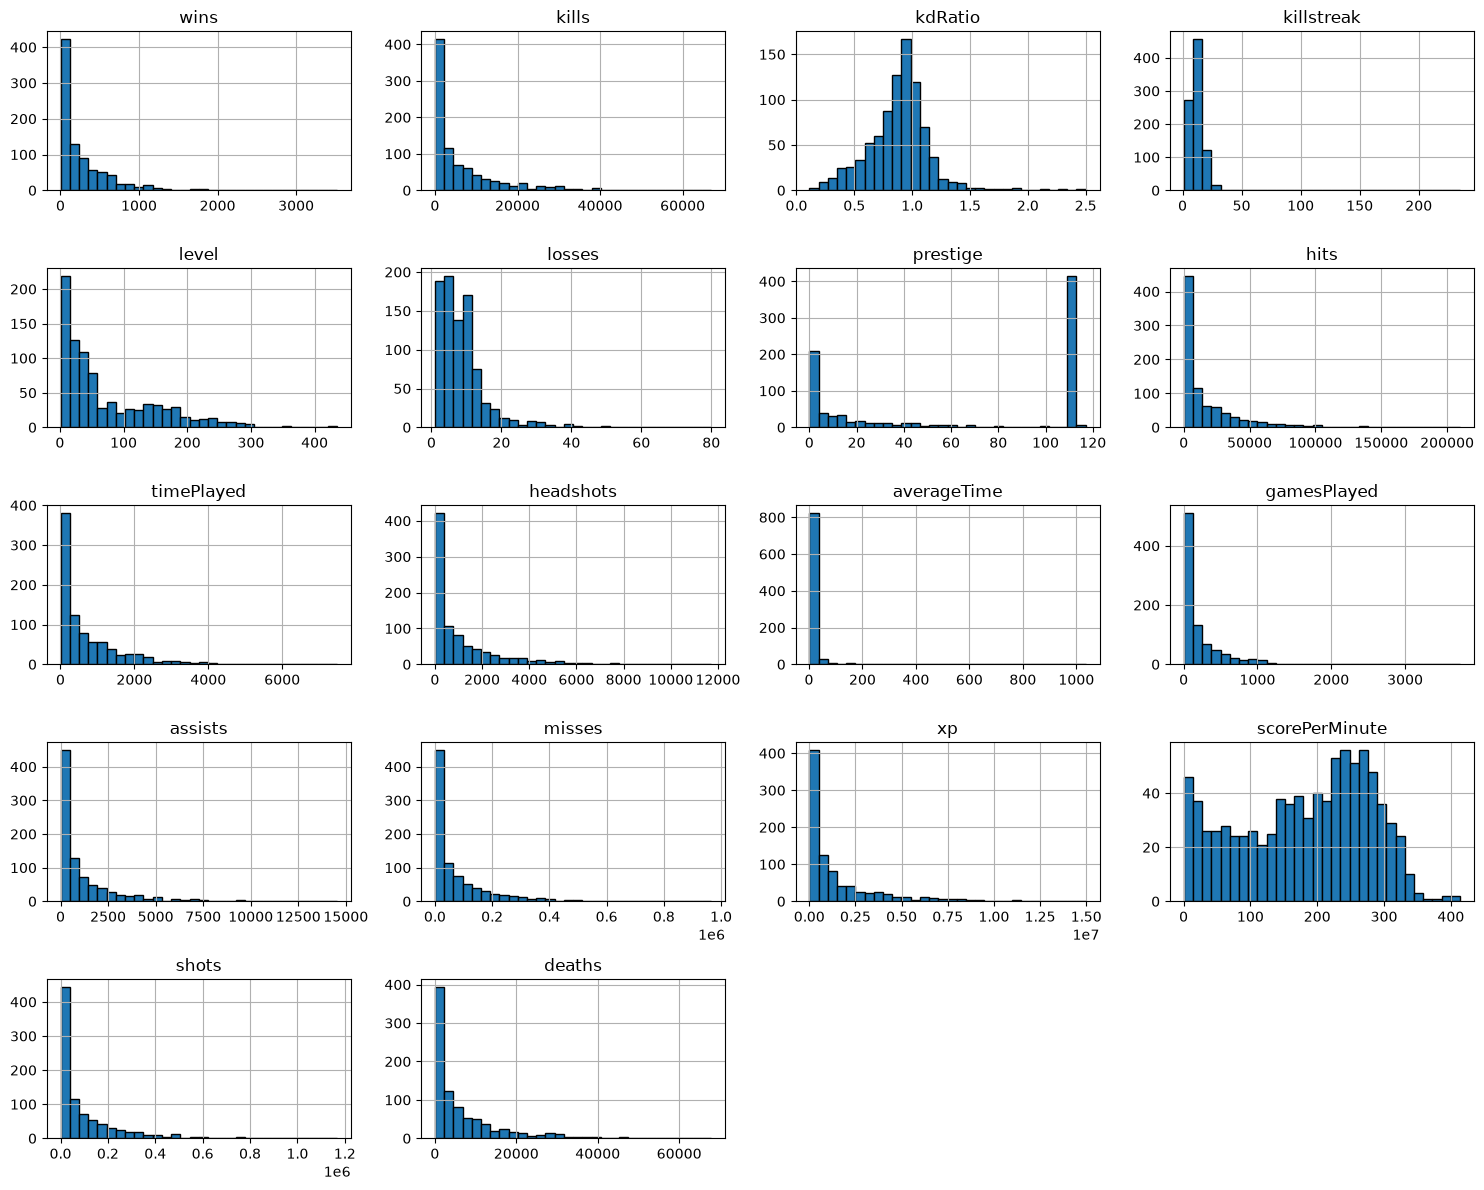

In [10]:
df.hist(bins=30, figsize=(15, 12), edgecolor='black')
plt.tight_layout()
plt.show()

The only approximately normal (Gaussian) distribution is **kdRatio**. This makes sense: this value can move in both directions for every player. A player can improve or get worse, but most players stay close to the mean, and therefore also close to the median.

In contrast, other columns such as **gamesPlayed** or **headshots** are right-skewed: most players are close to zero, and the further along the x-axis, the fewer players there are. This also makes sense, because these counters never decrease, they only accumulate, so players who have played longer should have higher values in these columns. All of this should therefore correlate with **timePlayed**.

Let's plot the correlation matrix to verify this.

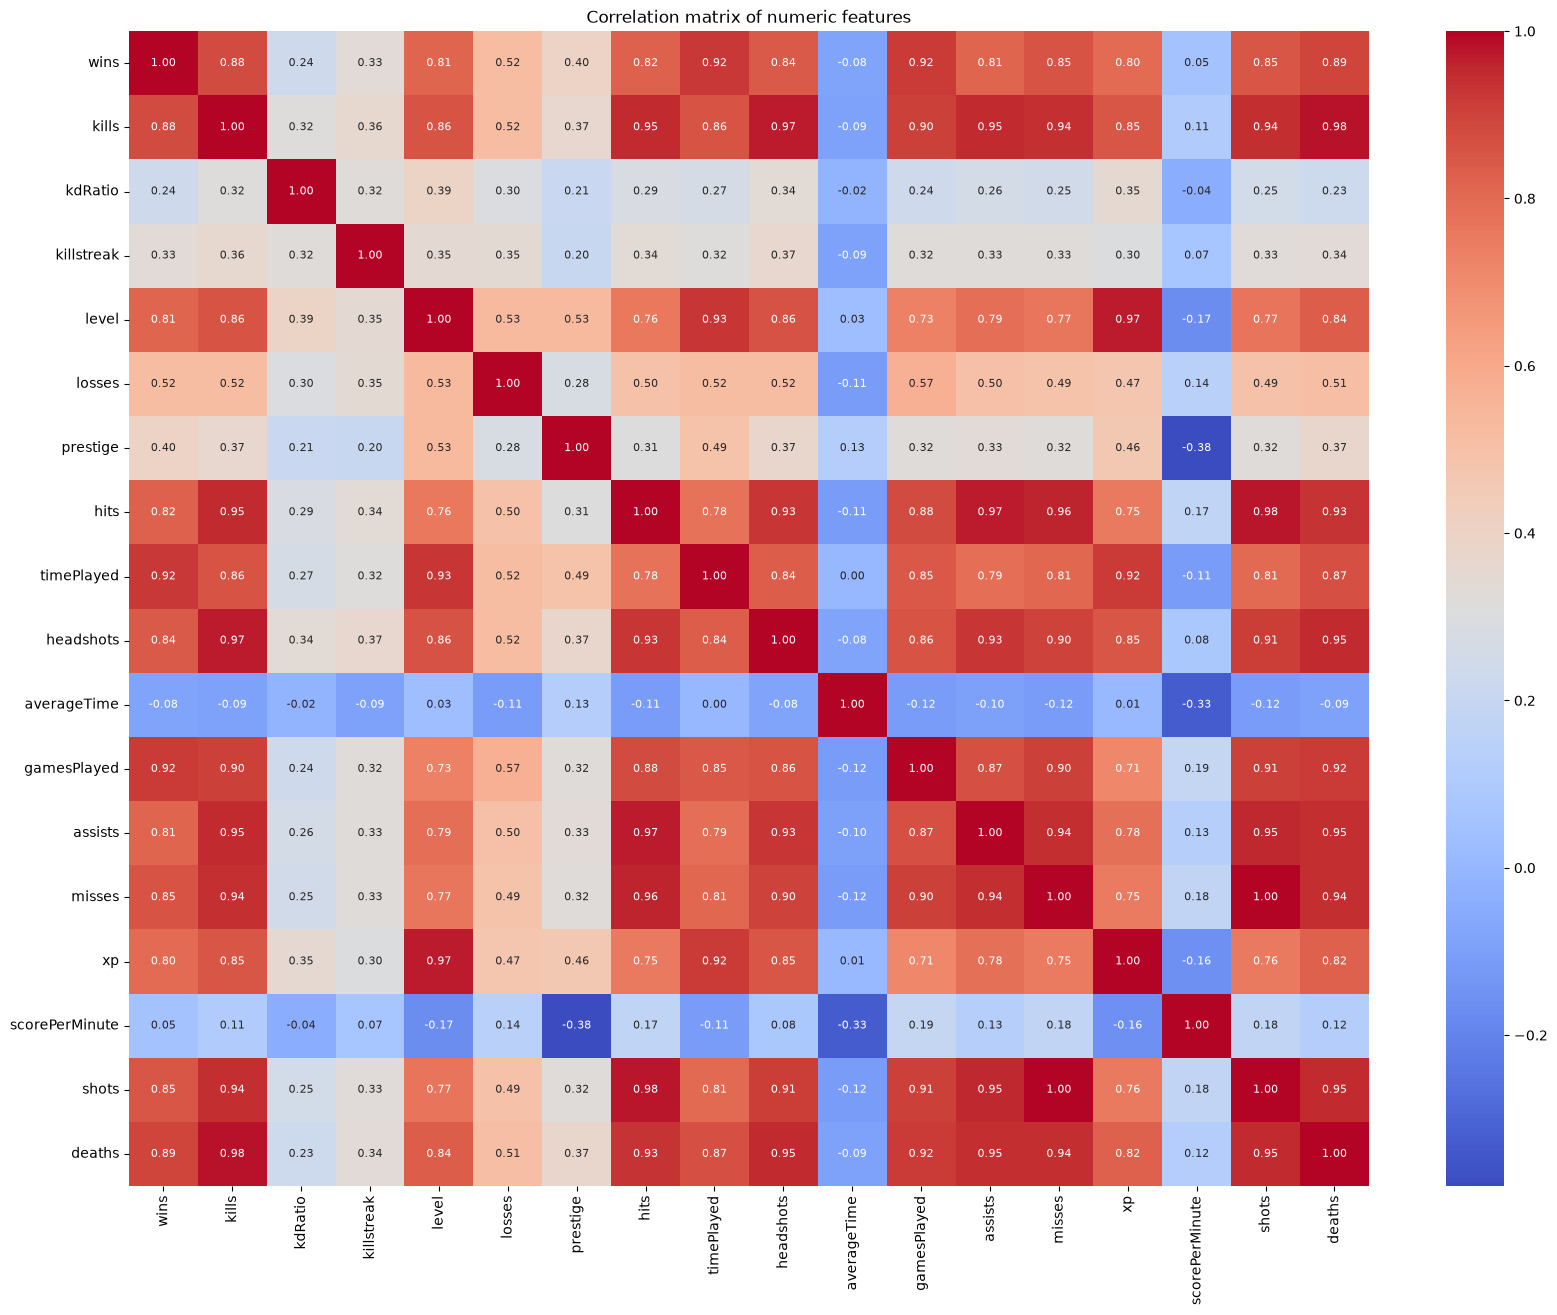

In [11]:
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(20, 15))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={"size": 8})
plt.title('Correlation matrix of numeric features')
plt.show()

The correlation matrix shows that many columns are correlated with others, which is expected. A **kill** requires a **hit** on the enemy, but not the other way round: a player can hit an enemy without killing them, which counts only as an **assist**.

Based on the correlation matrix and the meaning of the data, I derived more informative ratio features, replacing strongly correlated raw counts with less correlated ones:
* accuracy (hits/shots) - how accurate the player is
* miss_rate (misses/shots) - how inaccurate the player is
* headshot_rate (headshots/shots) - how precise the player's aim is
* score_rate (scorePerMinute * 60/time_played) - how active the player is in the game
* winrate (win/gamesPlayed) - how often the player wins
* trueLevel (xp/level) - XP per level, a proxy for the player's actual progression

The next step is to copy all columns needed for clustering into a new DataFrame.

In [12]:
df['accuracy'] = df['hits'] / df['shots']
df['miss_rate'] = df['misses'] / df['shots']
df['headshot_rate'] = df['headshots'] / df['shots']
df['score_rate'] = df['scorePerMinute'] * 60 / df['timePlayed']
df['winrate'] = df['wins'] / df['gamesPlayed']
df['trueLevel'] = df['xp'] / df['level']

df.replace([np.inf, -np.inf, np.nan], 0, inplace=True)

df_copy = df[['kdRatio', 'killstreak', 'trueLevel', 'timePlayed', 'gamesPlayed', 'accuracy', 'miss_rate', 'headshot_rate', 'score_rate', 'winrate']].copy()

df_copy.head()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
5,1.066743,18,22216.581921,1366,588,0.243606,0.756394,0.012667,11.230104,1.163265
6,0.632812,4,4080.833333,8,4,0.105107,0.894893,0.006477,1991.250000,1.000000
7,0.569628,13,12385.648649,550,150,0.113354,0.886646,0.010757,19.677779,1.240000
8,1.036658,26,23077.675676,2442,864,0.199126,0.800874,0.009530,4.885608,0.857639
9,0.444020,7,6063.750000,44,15,0.170548,0.829452,0.006849,345.923554,1.733333


In [13]:
df_copy.describe().T

,count,mean,std,min,25%,50%,75%,max
kdRatio,876.0,0.882819,0.268593,0.111111,0.745636,0.907812,1.018932,2.500000
killstreak,876.0,12.062785,11.079120,1.000000,8.000000,11.000000,15.000000,235.000000
trueLevel,876.0,13189.247650,7284.268884,725.000000,6814.140625,13658.803433,17022.034733,34415.032184
timePlayed,876.0,730.858447,936.290734,2.000000,71.750000,364.000000,1058.000000,7479.000000
gamesPlayed,876.0,207.507991,313.175564,1.000000,13.000000,80.000000,266.250000,3745.000000
accuracy,876.0,0.176802,0.045276,0.030710,0.148223,0.180427,0.206332,0.390244
miss_rate,876.0,0.823203,0.045285,0.609756,0.793668,0.819573,0.851777,0.969290
headshot_rate,876.0,0.025345,0.116773,0.000480,0.007744,0.010305,0.014612,2.167464
score_rate,876.0,277.236859,856.712183,0.009114,7.129759,25.083241,143.530989,9621.000000
winrate,876.0,3.160995,11.706623,0.133333,1.000000,1.264790,2.000000,254.000000


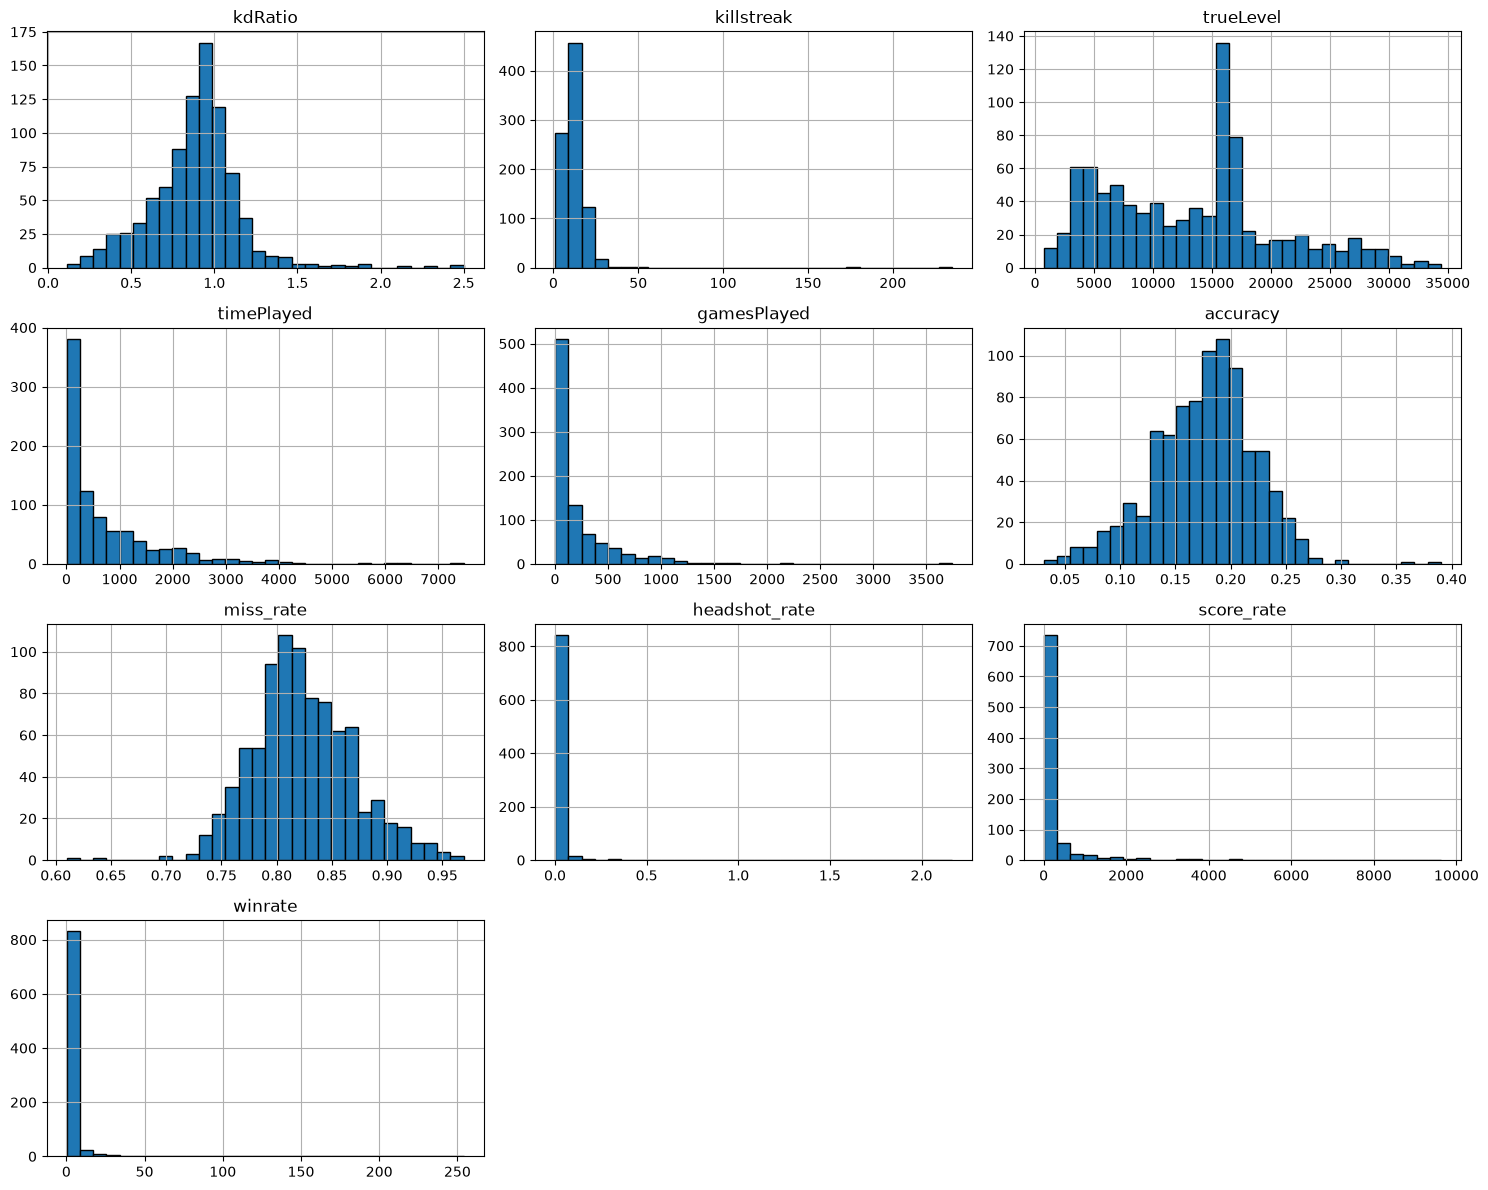

In [14]:
df_copy.hist(bins=30, figsize=(15, 12), edgecolor='black')
plt.tight_layout()
plt.show()

More columns now have an approximately normal distribution, namely **accuracy**, **score_rate**, **miss_rate** and again **kdRatio**. Let's plot the correlation matrix again to check that the correlations are now less extreme.

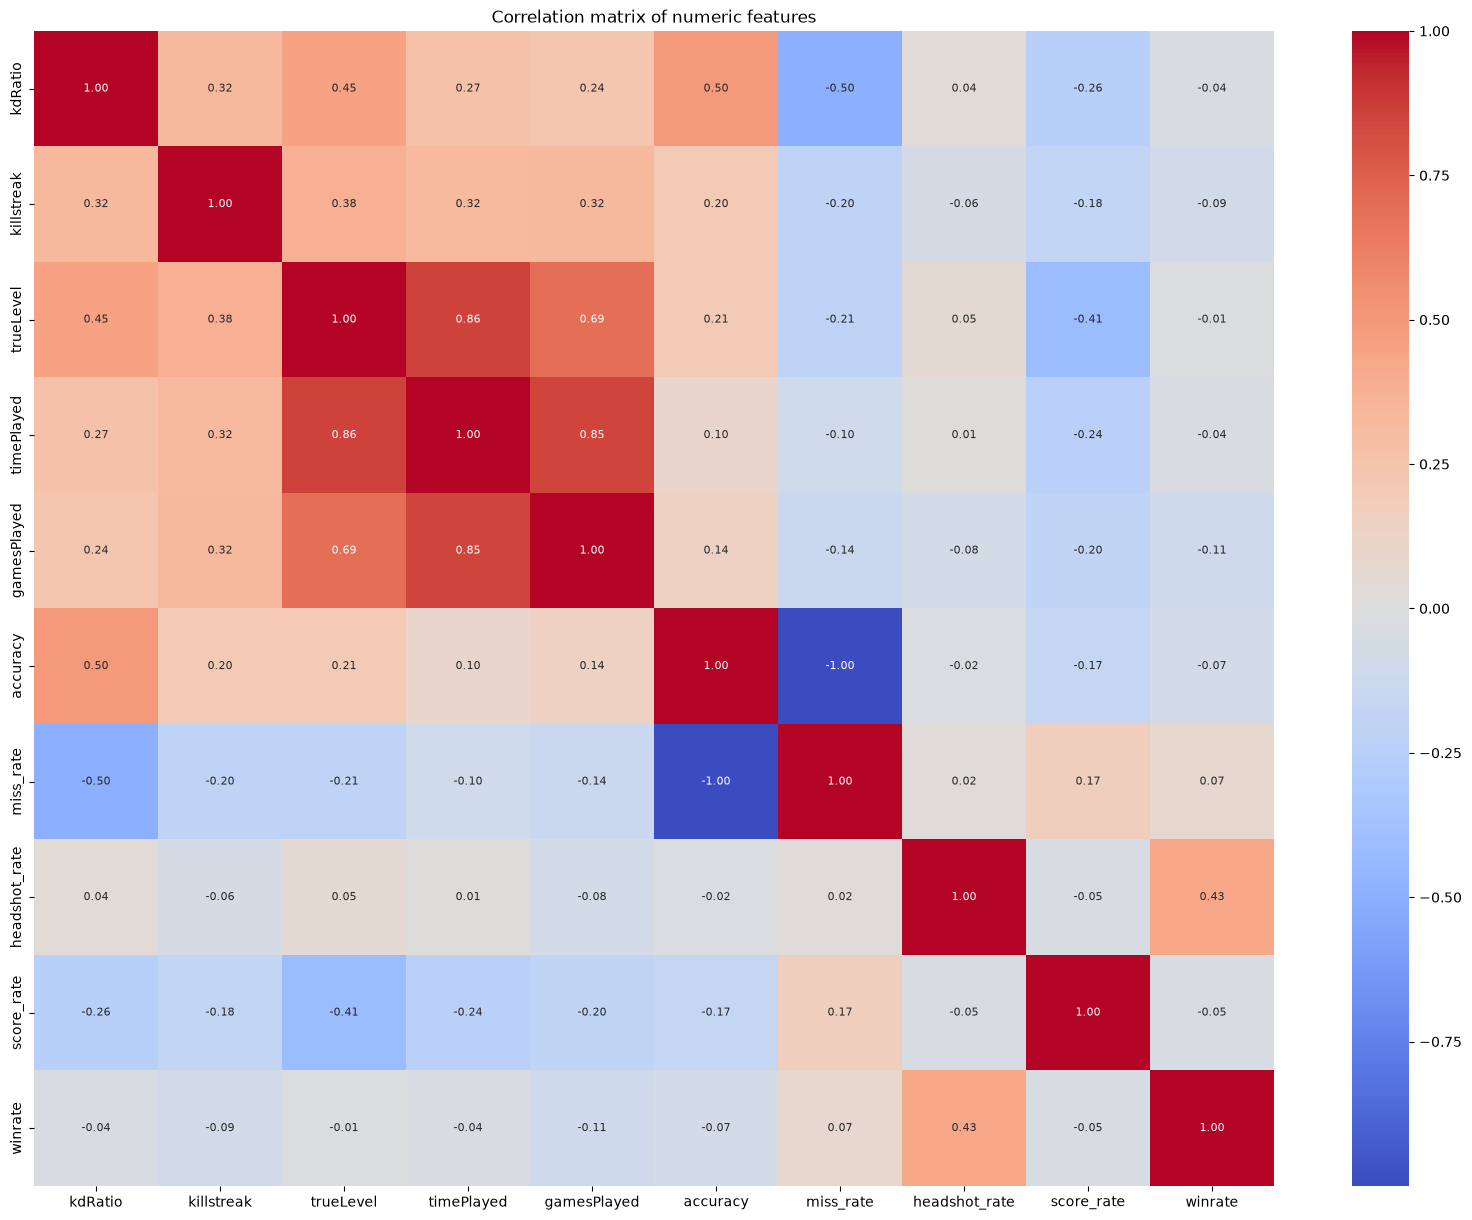

In [15]:
numeric_df = df_copy.select_dtypes(include=[np.number])

plt.figure(figsize=(20, 15))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={"size": 8})
plt.title('Correlation matrix of numeric features')
plt.show()

# Clustering experiments

### K-Means + Standard scaler

The first experiment uses **standard scaling with the K-Means algorithm**.

In [16]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_copy.select_dtypes(include='number'))

scaled_df_1 = pd.DataFrame(scaled_data, columns=df_copy.select_dtypes(include='number').columns)
scaled_df_1.head()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
0,0.685160,0.536198,1.240000,0.678747,1.215642,1.476333,-1.476148,-0.108632,-0.310675,-0.170747
1,-0.931334,-0.728162,-1.251137,-0.772486,-0.650192,-1.584406,1.583968,-0.161673,2.001830,-0.184701
2,-1.166711,0.084641,-0.110383,-0.193275,-0.183734,-1.402169,1.401768,-0.125001,-0.300808,-0.164188
3,0.573088,1.258690,1.358280,1.828619,2.097440,0.493339,-0.493354,-0.135508,-0.318084,-0.196869
4,-1.634629,-0.457227,-0.978762,-0.734014,-0.615048,-0.138212,0.138068,-0.158480,0.080221,-0.122023


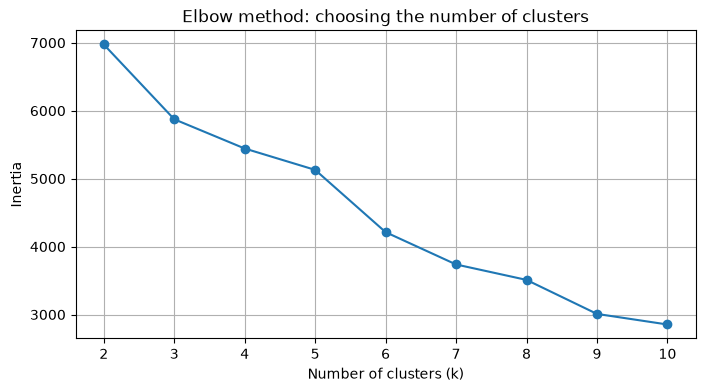

In [17]:
sse = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_df_1)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, sse, marker='o')
plt.title('Elbow method: choosing the number of clusters')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

Silhouette score for k=2: 0.2415
Silhouette score for k=3: 0.2698
Silhouette score for k=4: 0.1936
Silhouette score for k=5: 0.1901
Silhouette score for k=6: 0.2021


Silhouette score for k=7: 0.2286
Silhouette score for k=8: 0.2158
Silhouette score for k=9: 0.2384
Silhouette score for k=10: 0.2170


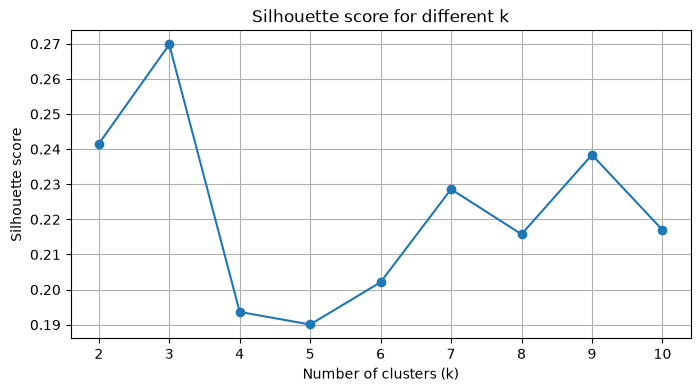

In [18]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(scaled_df_1)
    score = silhouette_score(scaled_df_1, labels)
    silhouette_scores.append(score)
    print(f'Silhouette score for k={k}: {score:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette score for different k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

The elbow method was inconclusive, so I also computed the silhouette score. It is highest for 3 clusters, so K-Means is run with k = 3 from here on.

In [19]:
kmeans = KMeans(n_clusters=3, random_state=42)
df_cluster1 = df_copy.copy()
df_cluster1['cluster_exp1'] = kmeans.fit_predict(scaled_df_1)
print(f"Number of samples in each cluster:\n{df_cluster1['cluster_exp1'].value_counts()}")

Number of samples in each cluster:
cluster_exp1
0    464
1    241
2    171
Name: count, dtype: int64


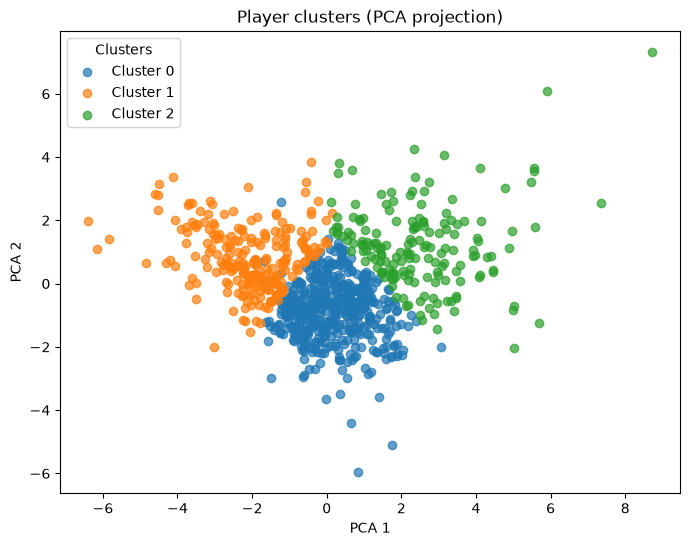

In [20]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(scaled_df_1)

plt.figure(figsize=(8,6))

clusters = np.unique(df_cluster1['cluster_exp1'])

for cluster in clusters:
    idx = df_cluster1['cluster_exp1'] == cluster
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=f'Cluster {cluster}', alpha=0.7)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Player clusters (PCA projection)")
plt.legend(title="Clusters")
plt.show()

In [21]:
df_cluster1.groupby('cluster_exp1').mean()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
cluster_exp1,,,,,,,,,,
0,0.964580,11.900862,12326.060144,440.771552,122.627155,0.199316,0.800684,0.033923,144.093294,3.528642
1,0.627589,6.937759,7482.526960,212.560166,46.518672,0.127673,0.872346,0.016165,726.176848,3.544757
2,1.020675,19.725146,23574.269225,2248.461988,664.719298,0.184951,0.815049,0.015006,5.798712,1.622544


#### Evaluation
K-Means with standard scaling produces 3 clusters.

**Cluster 0** - Average players
* Largest cluster

This cluster represents the average: players who do not stand out in any way. All their stats lie between clusters 1 and 2.

**Cluster 1** - Newcomers
* Lowest kdRatio
* Lowest level
* Fewest hours / matches played
* Highest score per hour
* Highest winrate

These are clearly players who have only just started playing or have played very little. They have the lowest level, the least playtime and the fewest matches, which in turn inflates their score per hour and winrate. Their accuracy confirms that they are beginners: they have the lowest accuracy and the highest share of missed shots of all clusters.

**Cluster 2** - Top players
* Highest kdRatio
* Highest level
* Most hours / matches played
* Lowest score per hour
* Lowest winrate

This group is the exact opposite of cluster 1. These are dedicated and also the strongest players. This is reflected in their average level, the highest kdRatio, the most hours / matches played and even the highest average killstreak. Their average score per hour and winrate are the lowest, but that makes sense: they have also played the most matches, which pulls these averages down considerably. According to the data, these are the most experienced players in the game.

### K-Means + Log-transform

In [22]:
df_numeric = df_copy.select_dtypes(include='number')
df_log = np.log1p(df_numeric)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_log)

scaled_df_2 = pd.DataFrame(scaled_data, columns=df_numeric.columns)
scaled_df_2.head()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
0,0.722005,0.996759,1.047004,0.955671,1.234820,1.446737,-1.493525,-0.128287,-0.546791,-0.394464
1,-0.924725,-1.583809,-1.432534,-1.930366,-1.363603,-1.605824,1.568148,-0.215115,2.033453,-0.521315
2,-1.200488,0.406454,0.191976,0.433615,0.493188,-1.413625,1.392218,-0.155026,-0.280739,-0.338117
3,0.619544,1.676014,1.102651,1.289258,1.444211,0.505093,-0.484674,-0.172216,-0.917324,-0.640680
4,-1.783292,-0.675288,-0.853095,-1.005668,-0.729851,-0.118506,0.150425,-0.209873,1.147935,-0.016355


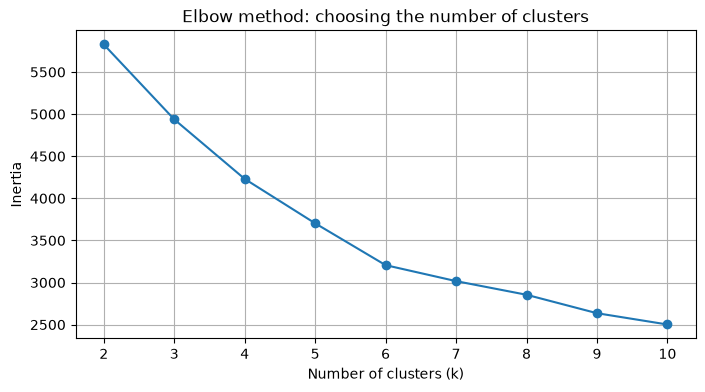

In [23]:
sse = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_df_2)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, sse, marker='o')
plt.title('Elbow method: choosing the number of clusters')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

Silhouette score for k=2: 0.3649
Silhouette score for k=3: 0.3744
Silhouette score for k=4: 0.2994
Silhouette score for k=5: 0.2398
Silhouette score for k=6: 0.2464
Silhouette score for k=7: 0.2181
Silhouette score for k=8: 0.2177


Silhouette score for k=9: 0.2099
Silhouette score for k=10: 0.1968


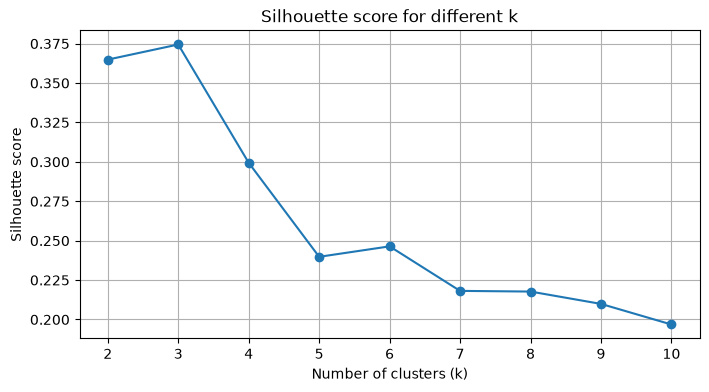

In [24]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(scaled_df_2)
    score = silhouette_score(scaled_df_2, labels)
    silhouette_scores.append(score)
    print(f'Silhouette score for k={k}: {score:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette score for different k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

In [25]:
kmeans = KMeans(n_clusters=3, random_state=42)
df_cluster2 = df_copy.copy()
df_cluster2['cluster_exp2'] = kmeans.fit_predict(scaled_df_2)
print(f"Number of samples in each cluster:\n{df_cluster2['cluster_exp2'].value_counts()}")

Number of samples in each cluster:
cluster_exp2
1    532
2    276
0     68
Name: count, dtype: int64


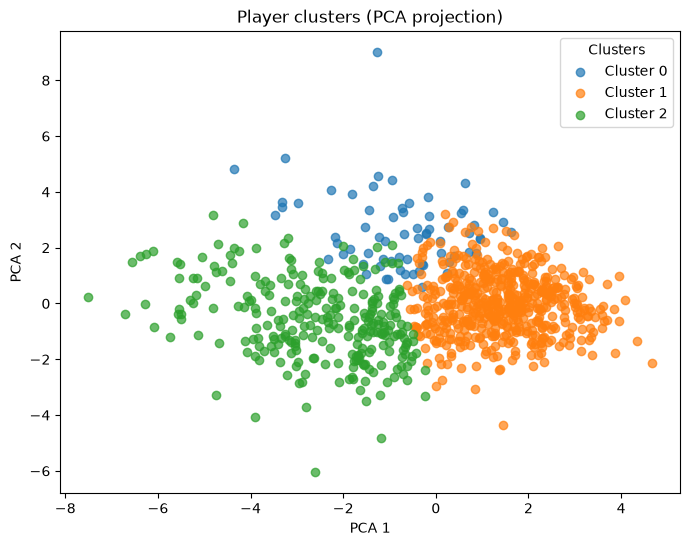

In [26]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(scaled_df_2)

plt.figure(figsize=(8,6))

clusters = np.unique(df_cluster2['cluster_exp2'])

for cluster in clusters:
    idx = df_cluster2['cluster_exp2'] == cluster
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=f'Cluster {cluster}', alpha=0.7)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Player clusters (PCA projection)")
plt.legend(title="Clusters")
plt.show()

In [27]:
df_cluster2.groupby('cluster_exp2').mean()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
cluster_exp2,,,,,,,,,,
0,0.775092,7.250000,13434.398178,583.279412,16.132353,0.148278,0.851789,0.179639,4.910759,21.081512
1,0.983237,15.381579,17311.947551,1102.152256,331.357143,0.189671,0.810329,0.013732,26.667347,1.506970
2,0.715802,6.851449,5182.194814,51.536232,15.934783,0.159025,0.840975,0.009715,827.313508,1.933988


#### Evaluation
Again 3 clusters, but compared with the first experiment (standard scaling only), the players are now split differently.

**Cluster 0** - Mixed players
* Fewest players
* Many hours played
* Few matches played
* Low score
* High winrate

The smallest group. It contains both weak and very strong players; the cluster looks unusual and may also contain suspicious players. Their kdRatio is fairly good, as are their headshot rate and winrate (the highest of all clusters), but this does not match their low number of matches or their miss rate (they miss often), and their score per hour is also low. One possible explanation for the large playtime that the other stats do not reflect is that these players spend a lot of time in menus. Another is that this group contains players with incomplete data (e.g. zero values in one column while the others are normal), which heavily distorts the statistics.


**Cluster 1** - Other players
* Most hours and matches played
* Best kdRatio and level
* Lowest winrate

This cluster now contains most players (~500): above-average and average players. Their winrate is again the lowest, because this cluster also has the most hours and matches played, which lowers the winrate. This suggests that the longer players play, the more their winrate stabilizes at around 1.5.


**Cluster 2** - Newcomers / weakest players

These are the weakest players. Compared with the previous two clusters, the biggest difference is again in hours played and trueLevel. Their kdRatio is not that different from the other two groups. However, their winrate is higher than that of cluster 1, which again supports the observation that the longer players play, the more stable their winrate becomes. With few matches played, their share of wins is high. The same applies to their score_rate.

### DBSCAN - Standard scaler

In [28]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_copy.select_dtypes(include='number'))

scaled_df_3 = pd.DataFrame(scaled_data, columns=df_copy.select_dtypes(include='number').columns)
scaled_df_3.head()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
0,0.685160,0.536198,1.240000,0.678747,1.215642,1.476333,-1.476148,-0.108632,-0.310675,-0.170747
1,-0.931334,-0.728162,-1.251137,-0.772486,-0.650192,-1.584406,1.583968,-0.161673,2.001830,-0.184701
2,-1.166711,0.084641,-0.110383,-0.193275,-0.183734,-1.402169,1.401768,-0.125001,-0.300808,-0.164188
3,0.573088,1.258690,1.358280,1.828619,2.097440,0.493339,-0.493354,-0.135508,-0.318084,-0.196869
4,-1.634629,-0.457227,-0.978762,-0.734014,-0.615048,-0.138212,0.138068,-0.158480,0.080221,-0.122023


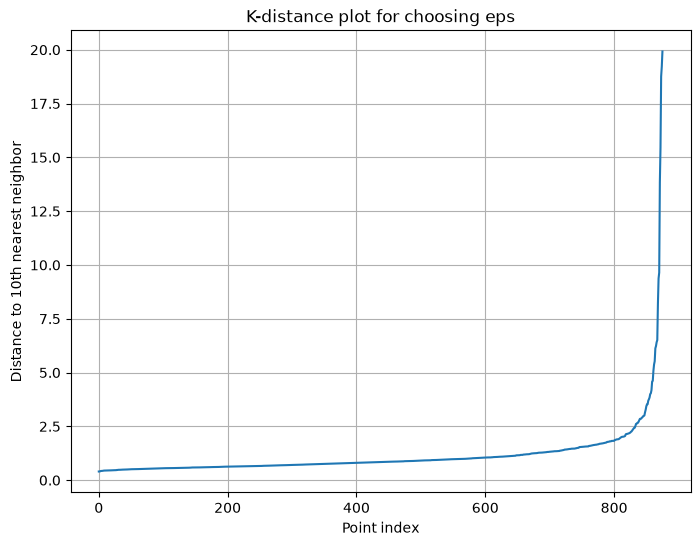

In [29]:
min_samples = 10
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(scaled_df_3)
distances, indices = neighbors_fit.kneighbors(scaled_df_3)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8,6))
plt.plot(k_distances)
plt.xlabel("Point index")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("K-distance plot for choosing eps")
plt.grid(True)
plt.show()

In [30]:
dbscan = DBSCAN(eps=5.5, min_samples=min_samples, metric='manhattan')
df_cluster3 = df_copy.copy()
df_cluster3['cluster_exp3'] = dbscan.fit_predict(scaled_df_3)
print(f"Number of samples in each cluster:\n{df_cluster3['cluster_exp3'].value_counts()}")

Number of samples in each cluster:
cluster_exp3
 0    860
-1     16
Name: count, dtype: int64


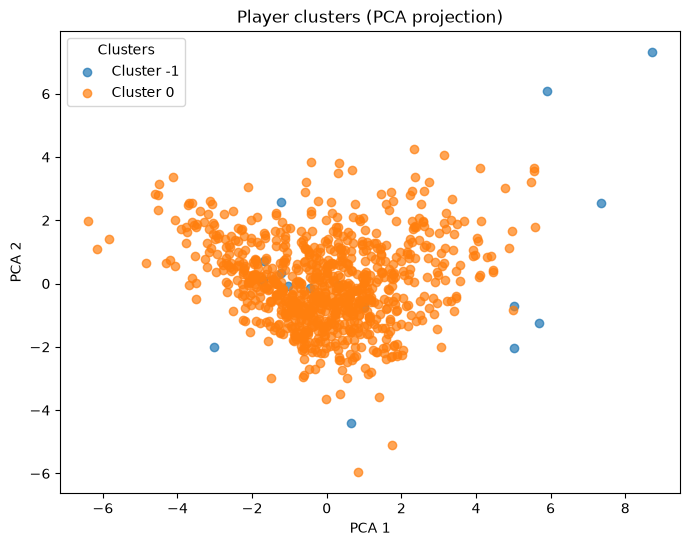

In [31]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(scaled_df_3)

plt.figure(figsize=(8,6))

clusters = np.unique(df_cluster3['cluster_exp3'])

for cluster in clusters:
    idx = df_cluster3['cluster_exp3'] == cluster
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=f'Cluster {cluster}', alpha=0.7)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Player clusters (PCA projection)")
plt.legend(title="Clusters")
plt.show()

DBSCAN can detect outliers (noise), which are labelled as cluster -1.

In [32]:
df_cluster3.groupby('cluster_exp3').mean()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
cluster_exp3,,,,,,,,,,
-1,1.162454,36.375000,17182.073624,1632.875000,455.000000,0.191180,0.808820,0.503151,625.633324,40.961920
0,0.877617,11.610465,13114.962516,714.076744,202.903488,0.176535,0.823471,0.016456,270.755064,2.457722


#### Evaluation
DBSCAN produces only two groups: cluster 0 and cluster -1, which DBSCAN treats as outliers.

**Cluster -1** - Outlier players
* Smaller group

These players differ from the rest in how they play, which is why they are outliers. They exceed the other players on all attributes: they play more than others (level, timePlayed, gamesPlayed) and are also above average in play quality (kdRatio, accuracy, winrate). This matches the nature of DBSCAN: the dataset is not split into well-separated clusters, values transition gradually from player to player, so DBSCAN detected only the main "average" group and this group of outliers.


**Cluster 0** - Other players (average)
* Larger group

This cluster contains all the other players, which is why it is much larger than cluster -1. Their values reflect this.


Tuning DBSCAN further by increasing eps would merge more and more points into the main cluster, until no player would be an outlier. Conversely, decreasing eps and min_samples would increase the number of outliers detected. This approach could be an interesting starting point for detecting cheating players. With proper tuning, the outlier cluster could surface players who have very few hours and matches played but whose performance exceeds that of most players. Such players could then be prioritized for review, or flagged automatically, e.g. combined with a threshold on how often they are reported by other players.

### Hierarchical - MinMax scaler

In [33]:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df_copy.select_dtypes(include='number'))

scaled_df_4 = pd.DataFrame(scaled_data, columns=df_copy.select_dtypes(include='number').columns)
scaled_df_4.head()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
0,0.400032,0.072650,0.637921,0.182426,0.156784,0.592146,0.407854,0.005624,0.001166,0.004057
1,0.218387,0.012821,0.099609,0.000802,0.000801,0.206927,0.793073,0.002767,0.206968,0.003414
2,0.191937,0.051282,0.346116,0.073291,0.039797,0.229863,0.770137,0.004742,0.002044,0.004359
3,0.387438,0.106838,0.663480,0.326334,0.230502,0.468428,0.531572,0.004176,0.000507,0.002853
4,0.139357,0.025641,0.158467,0.005617,0.003739,0.388942,0.611058,0.002939,0.035954,0.006303


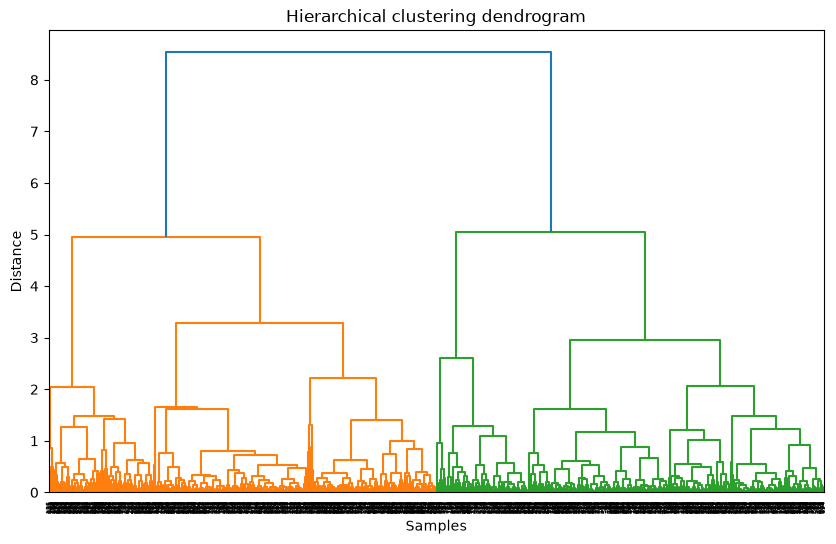

In [34]:
linked = linkage(scaled_df_4, method='ward')
plt.figure(figsize=(10, 6))
dendrogram(linked)
plt.title("Hierarchical clustering dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

In [35]:
hier = AgglomerativeClustering(n_clusters=4, linkage='ward')
df_cluster4 = df_copy.copy()
df_cluster4['cluster_exp4'] = hier.fit_predict(scaled_df_4)
print(f"Number of samples in each cluster:\n{df_cluster4['cluster_exp4'].value_counts()}")

Number of samples in each cluster:
cluster_exp4
1    334
0    319
3    119
2    104
Name: count, dtype: int64


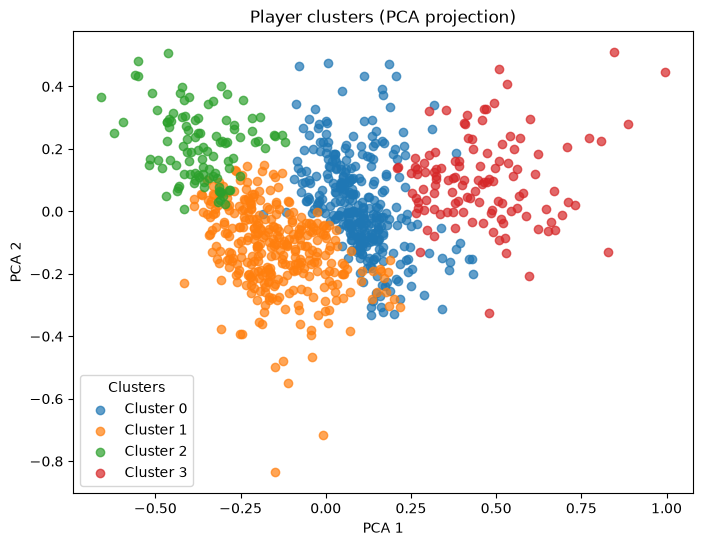

In [36]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(scaled_df_4)

plt.figure(figsize=(8,6))

clusters = np.unique(df_cluster4['cluster_exp4'])

for cluster in clusters:
    idx = df_cluster4['cluster_exp4'] == cluster
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=f'Cluster {cluster}', alpha=0.7)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Player clusters (PCA projection)")
plt.legend(title="Clusters")
plt.show()

In [37]:
df_cluster4.groupby('cluster_exp4').mean()

,kdRatio,killstreak,trueLevel,timePlayed,gamesPlayed,accuracy,miss_rate,headshot_rate,score_rate,winrate
cluster_exp4,,,,,,,,,,
0,0.923405,14.692790,16592.088682,891.677116,253.504702,0.178380,0.821634,0.043992,15.431776,4.263758
1,0.901662,9.631737,8000.077524,137.700599,45.754491,0.193323,0.806677,0.013915,385.604486,2.377942
2,0.486536,5.057692,5067.308695,75.961538,17.163462,0.105984,0.894016,0.014921,1044.706481,3.898935
3,1.067467,17.957983,25730.072729,2536.932773,704.554622,0.188093,0.811907,0.016547,4.162855,1.757738


#### Evaluation
Here the best split is 4 clusters.

**Cluster 0** - Average players

Players I consider average. Their stats are very good, but not enough to match the top players in cluster 3.

**Cluster 1** - Weak players

Below-average players. They play fairly poorly, which is consistent with their relatively low playtime. They are not as weak as the next cluster of newcomers / weakest players, though.

**Cluster 2** - Newcomers / weakest players
- Fewest players

This cluster represents either newcomers or very weak players who contribute little to their matches.

**Cluster 3** - Top players

The best players of all. They have the most hours played and also achieve the best results.

# Conclusion



The dataset describes individual players and how they perform in Call of Duty: Modern Warfare. What interested me was the possibility of using this data to determine which categories of players exist in the game and, for example, to identify outlying groups that differ from the rest.

**EDA**
The first part of the project was EDA, where I visualized and analyzed the dataset. Although it contains no categorical data that would need special handling before clustering, its numeric attributes span very wide ranges and it contains zero values. A player with a zero value in one of the key columns should not be considered for clustering, so these players were removed.

Another important EDA step was the correlation matrix. It showed that many columns depend on others, which makes sense in this case, as discussed above. I therefore derived new ratio features from the original columns, which say more about a player's skill.

**Preprocessing**
This step was already done as part of EDA, so that the data could be visualized correctly.

**Clustering experiments**
1. K-Means + standard scaler

The best number of clusters here was 3 (highest silhouette score). K-Means split the players by their skill into:

* Cluster 0 - Average players
* Cluster 1 - Newcomers
* Cluster 2 - Top players

2. K-Means + log-transform

Again, the best number of clusters was 3. In this case, however, K-Means did not split the players strictly by skill, but into:

* Cluster 0 - Mixed players
* Cluster 1 - Other players
* Cluster 2 - Newcomers / weakest players

3. DBSCAN + standard scaler

This algorithm determines the number of clusters itself, based on eps. I chose eps from the k-distance plot and tried values around 5.5. Increasing eps merged the outlier players into the main group; decreasing it produced more outliers.

* Cluster -1 - Outlier players
* Cluster 0 - Other players

4. Hierarchical + MinMax scaler

For hierarchical clustering I again needed to determine the optimal number of clusters. I used a dendrogram with Ward linkage, which works well for compact clusters (as in this dataset) but is sensitive to feature scaling. I addressed the scaling issue with a MinMax scaler.

The players were split into:

* Cluster 0 - Average players
* Cluster 1 - Weak players
* Cluster 2 - Newcomers / weakest players
* Cluster 3 - Top players


In conclusion, I was able to identify different player profiles in the dataset based on their playtime and in-game performance. DBSCAN could also be used to surface suspicious players who may not be playing fairly. This shows that data analysis is very valuable in the gaming industry, both for balancing mechanisms and for flagging suspicious players.